# F4_01 · Visualizaciones analíticas

**Objetivo:** _(completar)_ Comunicar, mediante tres visualizaciones, la proporción de egresos por colelitiasis con colecistectomía registrada en los grupos de riesgo de cáncer de vesícula, comparando las provincias de Cautín y Malleco (La Araucanía, 2022).

**Cómo se usa este notebook (para el grupo):**
- Parte del artefacto de F3 (`data/processed/egresos_araucania_k80_transformado.csv`): no se reprocesa la base nacional.
- Todas las figuras usan la misma `tabla`, los mismos colores (`COLORES`), los mismos nombres de grupo (`NOMBRES_GRUPO`) y la misma nota de fuente (`FUENTE`), para que se vean como un solo informe.
- Cada figura va en su sección, con su objetivo específico y un **título que diga el hallazgo**, no el tipo de gráfico.
- Cada figura se guarda con `guardar_figura(fig, "nombre")` en `F4/figuras/`, para usarla en el informe y en el video.
- Antes de subir: **Restart Kernel and Run All** sin errores.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Raíz del repositorio: funciona si el notebook se abre desde su carpeta (F1, F2...) o desde la raíz
RAIZ = Path.cwd()
RAIZ = RAIZ.parent if RAIZ.name.startswith("F") else RAIZ
sys.path.insert(0, str(RAIZ))

from src.entorno import verificar_entorno
from src.proporciones import CalcNumpy

versiones = verificar_entorno()

# Estilo común de las tres figuras
COLORES = {"Cautín": "#1f77b4", "Malleco": "#d95f02"}
NOMBRES_GRUPO = {
    "GRUPO_RIESGO_MUJER": "Mujeres",
    "GRUPO_RIESGO_ETNIA": "Pertenencia a etnia",
    "GRUPO_RIESGO_40_49": "40 a 49 años",
}
FUENTE = "Fuente: elaboración propia con datos de egresos hospitalarios DEIS, 2022."
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11, "axes.titlesize": 13})

CARPETA_FIG = RAIZ / "F4" / "figuras"
CARPETA_FIG.mkdir(parents=True, exist_ok=True)

def guardar_figura(fig, nombre):
    """Guarda la figura en F4/figuras/ en PNG, para el informe y el video."""
    ruta = CARPETA_FIG / f"{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    print("Figura guardada en:", ruta)

Versión de Python: 3.12.10
Entorno virtual del proyecto (.venv): True
pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2


## 1. Datos de partida: artefacto de F3

Se carga el archivo transformado en F2/F3 y se calculan las proporciones con la misma clase usada en F3 (`CalcNumpy`), que entrega para cada grupo y provincia el número de egresos, los egresos con colecistectomía, la proporción y su intervalo de Wilson al 95 %.

In [2]:
ENTRADA = RAIZ / "data" / "processed" / "egresos_araucania_k80_transformado.csv"
datos = pd.read_csv(ENTRADA)

calculador = CalcNumpy(datos)
tabla = calculador.calcular()
tabla["grupo_nombre"] = tabla["grupo"].map(NOMBRES_GRUPO)
for col in ["proporcion", "ic95_inf", "ic95_sup"]:
    tabla[col + "_%"] = (tabla[col] * 100).round(1)

print("Egresos analizados:", calculador.n_egresos)
tabla[["grupo_nombre", "provincia", "en_grupo", "egresos", "con_colecistectomia",
       "proporcion_%", "ic95_inf_%", "ic95_sup_%"]]

Egresos analizados: 3789


,grupo_nombre,provincia,en_grupo,egresos,con_colecistectomia,proporcion_%,ic95_inf_%,ic95_sup_%
0,40 a 49 años,Cautín,False,2496,2001,80.2,78.6,81.7
1,40 a 49 años,Cautín,True,521,465,89.3,86.3,91.6
2,40 a 49 años,Malleco,False,645,490,76.0,72.5,79.1
3,40 a 49 años,Malleco,True,127,100,78.7,70.8,85.0
4,Pertenencia a etnia,Cautín,False,2384,1967,82.5,80.9,84.0
5,Pertenencia a etnia,Cautín,True,633,499,78.8,75.5,81.8
6,Pertenencia a etnia,Malleco,False,652,505,77.5,74.1,80.5
7,Pertenencia a etnia,Malleco,True,120,85,70.8,62.2,78.2
8,Mujeres,Cautín,False,806,622,77.2,74.1,79.9
9,Mujeres,Cautín,True,2211,1844,83.4,81.8,84.9


## 2. Verificación: mismas cifras que el informe y el video

Si alguna de estas comprobaciones falla, el notebook se detiene: significa que los datos de partida cambiaron y las cifras del informe ya no coinciden.

In [3]:
assert calculador.n_egresos == 3789, "Cambió el número de egresos K80"
assert round(calculador.proporcion_global() * 100, 1) == 80.7, "Cambió la proporción global"
print("Cifras verificadas: 3.789 egresos y 80,7 % con colecistectomía.")

Cifras verificadas: 3.789 egresos y 80,7 % con colecistectomía.


## 3. Figura 1

**Responsable:** Sebastián
**Objetivo específico al que responde:** Mostrar la proporción de colecistectomía observada en cada grupo de riesgo, por provincia, con su incertidumbre.
**Qué muestra:** Proporción de colecistectomía por grupo de riesgo y provincia, con su intervalo de Wilson 95 %.
**Título (hallazgo):** En Malleco, la proporción de colecistectomía es menor que en Cautín en los tres grupos de riesgo.

Figura guardada en: C:\Users\yagam\Documents\proyecto-grupo2-mcdi500\F4\figuras\figura1.png


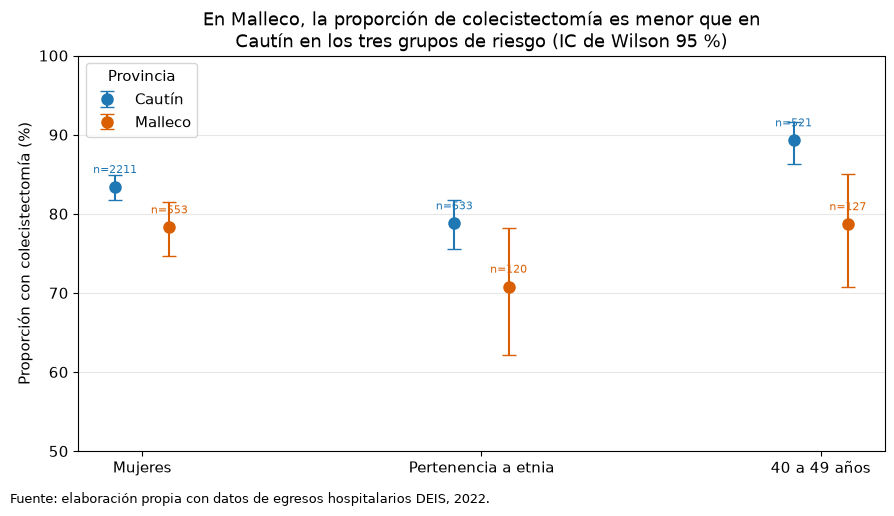

In [7]:
# Figura 1: proporción con colecistectomía por grupo de riesgo y provincia (IC de Wilson 95 %)
grupo1 = tabla[tabla["en_grupo"] == True].copy()
grupos_orden = list(NOMBRES_GRUPO.values())
x_base = {g: i for i, g in enumerate(grupos_orden)}
offset = {"Cautín": -0.08, "Malleco": 0.08}

fig, ax = plt.subplots()
for prov in COLORES:
    sub = grupo1[grupo1["provincia"] == prov].set_index("grupo_nombre").loc[grupos_orden]
    xs = [x_base[g] + offset[prov] for g in grupos_orden]
    ax.errorbar(xs, sub["proporcion_%"],
                yerr=[sub["proporcion_%"] - sub["ic95_inf_%"], sub["ic95_sup_%"] - sub["proporcion_%"]],
                fmt="o", capsize=5, color=COLORES[prov], label=prov, markersize=8)
    for x, y, n in zip(xs, sub["proporcion_%"], sub["egresos"]):
        ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(0, 10),
                    ha="center", fontsize=8, color=COLORES[prov])

ax.set_xticks(list(x_base.values()))
ax.set_xticklabels(grupos_orden)
ax.set_ylabel("Proporción con colecistectomía (%)")
ax.set_ylim(50, 100)
ax.set_title("En Malleco, la proporción de colecistectomía es menor que en\nCautín en los tres grupos de riesgo (IC de Wilson 95 %)")
ax.legend(title="Provincia")
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, -0.02, FUENTE, fontsize=9)
fig.tight_layout()
guardar_figura(fig, "figura1")

En los tres grupos de riesgo, Cautín registra una proporción más alta que Malleco: 83,4 % frente a 78,3 % en mujeres, 78,8 % frente a 70,8 % en quienes se identifican con una etnia, y 89,3 % frente a 78,7 % en el grupo de 40 a 49 años. Los intervalos de Wilson son más anchos en Malleco por el menor tamaño de sus grupos (entre 120 y 553 egresos, frente a 521-2.211 en Cautín), lo que exige leer esas diferencias con cautela.

## 4. Figura 2

**Responsable:** Constanza
**Objetivo específico al que responde:** _Comparar, dentro de cada provincia, la proporción de colecistectomía del grupo de riesgo frente a su grupo de referencia, para detectar brechas de acceso._
**Qué muestra:** Cada grupo de riesgo frente a su grupo de referencia (en_grupo True vs False), por provincia.
**Título (hallazgo):** _En Cautín, quienes se identifican con una etnia acceden menos a colecistectomía que el resto; en Malleco las diferencias no son concluyentes._

Figura guardada en: C:\Users\yagam\Documents\proyecto-grupo2-mcdi500\F4\figuras\figura2.png


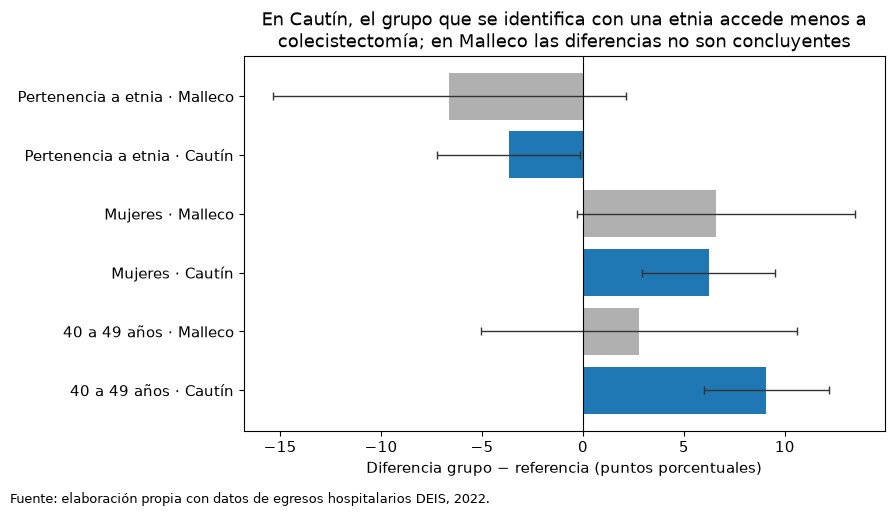

In [5]:
# Figura 2: diferencia grupo de riesgo (en_grupo=True) menos su referencia (False), por provincia
import numpy as np

filas = []
for (grupo, prov), g in tabla.groupby(["grupo_nombre", "provincia"]):
    ref = g[g["en_grupo"] == False].iloc[0]
    gr  = g[g["en_grupo"] == True].iloc[0]
    p1, n1 = gr["proporcion"],  gr["egresos"]
    p0, n0 = ref["proporcion"], ref["egresos"]
    dif = (p1 - p0) * 100  # puntos porcentuales
    se  = np.sqrt(p1*(1-p1)/n1 + p0*(1-p0)/n0) * 100
    filas.append({"grupo": grupo, "provincia": prov,
                  "dif": dif, "ic_inf": dif - 1.96*se, "ic_sup": dif + 1.96*se})

dif_tabla = pd.DataFrame(filas).sort_values(["grupo", "provincia"]).reset_index(drop=True)
dif_tabla["signif"] = (dif_tabla["ic_inf"] > 0) | (dif_tabla["ic_sup"] < 0)

fig, ax = plt.subplots()
y = np.arange(len(dif_tabla))
etiquetas = [f"{r.grupo} · {r.provincia}" for r in dif_tabla.itertuples()]
colores_barra = [COLORES[r.provincia] if r.signif else "#b0b0b0" for r in dif_tabla.itertuples()]

ax.barh(y, dif_tabla["dif"], color=colores_barra)
ax.errorbar(dif_tabla["dif"], y,
            xerr=[dif_tabla["dif"] - dif_tabla["ic_inf"], dif_tabla["ic_sup"] - dif_tabla["dif"]],
            fmt="none", ecolor="#333333", capsize=3, lw=1)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(etiquetas)
ax.set_xlabel("Diferencia grupo − referencia (puntos porcentuales)")
ax.set_title("En Cautín, el grupo que se identifica con una etnia accede menos a\ncolecistectomía; en Malleco las diferencias no son concluyentes")
fig.text(0.01, -0.02, FUENTE, fontsize=9)
plt.tight_layout()

guardar_figura(fig, "figura2")
plt.show()


**Lectura de la Figura 2:** _En Cautín, las tres diferencias son estadísticamente significativas: las mujeres (+6,2 pp) y el grupo de 40 a 49 años (+9,1 pp) acceden más que su grupo de referencia, mientras que quienes se identifican con una etnia acceden menos (−3,7 pp; 78,8 % frente a 82,5 %). En Malleco, en cambio, ninguna diferencia es concluyente, porque los intervalos de confianza cruzan el cero debido a los tamaños muestrales reducidos (por ejemplo, 120 egresos en el grupo de etnia). El contraste entre una brecha marcada en Cautín y la ausencia de señal en Malleco invita a observar con cautela el acceso del grupo de etnia en la provincia con más casos.)_

## 5. Figura 3

**Responsable:** Michael
**Objetivo específico al que responde:** _(completar)_
**Qué muestra:** Número de egresos sin colecistectomía registrada, por grupo de riesgo y provincia.
**Título (hallazgo):** _(completar con lo que muestra la figura, no con el tipo de gráfico)_

In [6]:
# Figura 3: usar `tabla`, `COLORES`, `NOMBRES_GRUPO` y `FUENTE`
# fig, ax = plt.subplots()
# ...
# fig.text(0.01, -0.02, FUENTE, fontsize=9)
# guardar_figura(fig, "figura3")

**Lectura de la Figura 3:** _(completar: qué se observa y qué cifras lo respaldan)_

## 6. Cierre

_(completar: síntesis de lo que muestran las tres figuras en relación con la pregunta de investigación)_